In [46]:
import pickle
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
import keras 
from keras.models import Sequential 
from keras.layers import LSTM, Dense
from sklearn.preprocessing import MinMaxScaler
from datetime import datetime

In [57]:

df = pd.read_pickle(r"C:\Users\valem\OneDrive\Documenti\weather_forecast\dfs.pickle")
print(df)

df['temp_mean_past1h'] = df['temp_mean_past1h'].fillna(0)
temperature = df["temp_mean_past1h"].values.reshape(-1, 1)
df['wind_speed_past1h'] = df['wind_speed_past1h'].fillna(0)
wind_speed = df["wind_speed_past1h"].values.reshape(-1, 1)


                      temp_mean_past1h  wind_speed_past1h
2025-10-09T22:00:00Z              11.8                4.5
2025-10-09T23:00:00Z              11.4                4.3
2025-10-10T00:00:00Z              11.3                4.5
2025-10-10T01:00:00Z              11.2                4.3
2025-10-10T02:00:00Z              11.4                4.3
...                                ...                ...
2025-11-09T18:00:00Z               6.7                2.3
2025-11-09T19:00:00Z               6.5                1.5
2025-11-09T20:00:00Z               5.9                1.3
2025-11-09T21:00:00Z               4.3                1.0
2025-11-09T22:00:00Z               4.3                0.2

[746 rows x 2 columns]


In [68]:
%pip install seaborn


  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [58]:

#scaling the temperature values between 0 and 1 for NNs
scaler = MinMaxScaler()
temp_scaled = scaler.fit_transform(temperature)
wind_scaled = scaler.fit_transform(wind_speed)

X_temp, y_temp = [], []
X_wind, y_wind = [], []

In [59]:
#LSTM format: xaxis sequence of 7 prev days, yaxis temp for the next 8 days

for i in range (7, len(temp_scaled)):
    X_temp.append(temp_scaled[i-7:i])
    y_temp.append(temp_scaled[i])
X_temp, y_temp = np.array(X_temp), np.array(y_temp)

In [60]:
for i in range (7, len(wind_scaled)):
    X_wind.append(wind_scaled[i-7:i])
    y_wind.append(wind_scaled[i])
X_wind, y_wind = np.array(X_wind), np.array(y_wind)

In [61]:
model = Sequential()
model.add(LSTM(50, activation='relu', input_shape=(7, 1)))
model.add(Dense(1))
model.compile(optimizer='adam', loss = 'mse')

model.fit(X_temp, y_temp, epochs=10, batch_size=8)

c:\Users\valem\OneDrive\Documenti\weather_forecast\.venv\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10
93/93 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - loss: 0.0652
Epoch 2/10
93/93 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - loss: 0.0073
Epoch 3/10
93/93 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - loss: 0.0067
Epoch 4/10
93/93 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0058
Epoch 5/10
93/93 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0051
Epoch 6/10
93/93 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0045
Epoch 7/10
93/93 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0037
Epoch 8/10
93/93 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0033
Epoch 9/10
93/93 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0031
Epoch 10/10
93/93 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0033


In [62]:
predicted_temp = model.predict(X_temp)
predicted_temp = scaler.inverse_transform(predicted_temp)

real_temp = scaler.inverse_transform(y_temp.reshape(-1, 1))

24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step


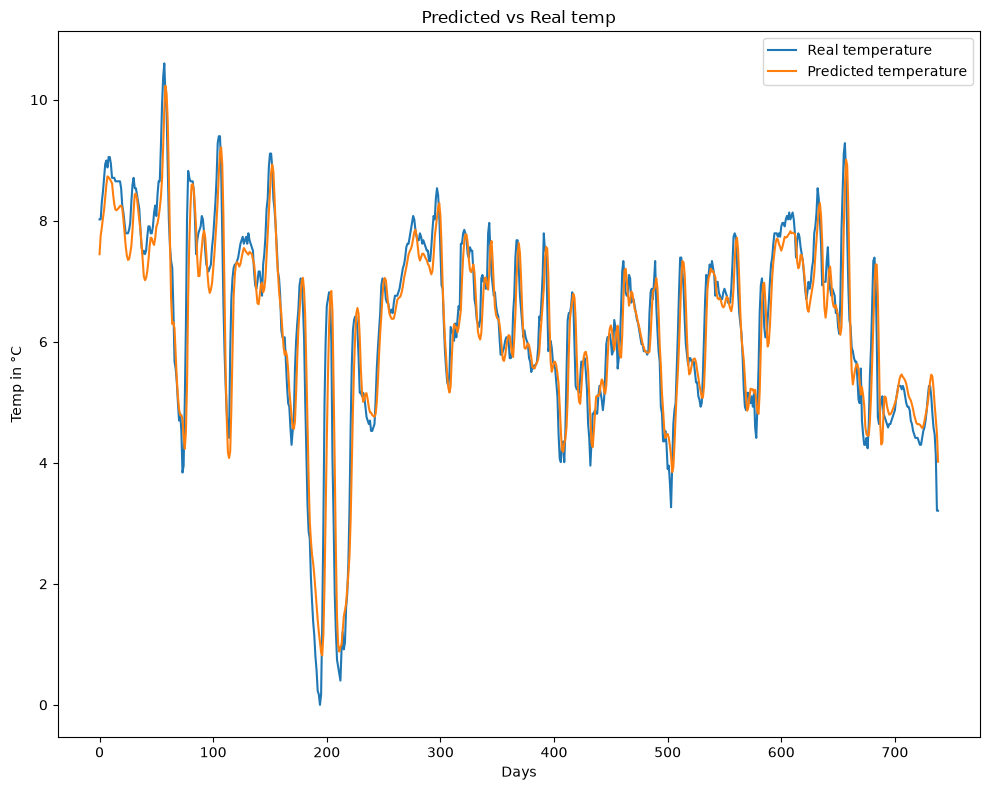

In [63]:
plt.figure(figsize=(10, 8))
plt.plot(real_temp, label='Real temperature')
plt.plot(predicted_temp, label='Predicted temperature')
plt.xlabel('Days')
plt.ylabel('Temp in °C')
plt.title('Predicted vs Real temp')
plt.legend()
plt.tight_layout()
plt.show()

In [64]:
model = Sequential()
model.add(LSTM(50, activation='relu', input_shape=(7, 1)))
model.add(Dense(1))
model.compile(optimizer='adam', loss = 'mse')

model.fit(X_wind, y_wind, epochs=10, batch_size=8)

Epoch 1/10


c:\Users\valem\OneDrive\Documenti\weather_forecast\.venv\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


93/93 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 0.0570
Epoch 2/10
93/93 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0130
Epoch 3/10
93/93 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0109
Epoch 4/10
93/93 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0098
Epoch 5/10
93/93 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0091
Epoch 6/10
93/93 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0085
Epoch 7/10
93/93 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0082
Epoch 8/10
93/93 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0081
Epoch 9/10
93/93 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0078
Epoch 10/10
93/93 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0077


In [65]:
predicted_speed = model.predict(X_wind)
predicted_speed = scaler.inverse_transform(predicted_speed)

real_speed = scaler.inverse_transform(y_wind.reshape(-1, 1))

24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step


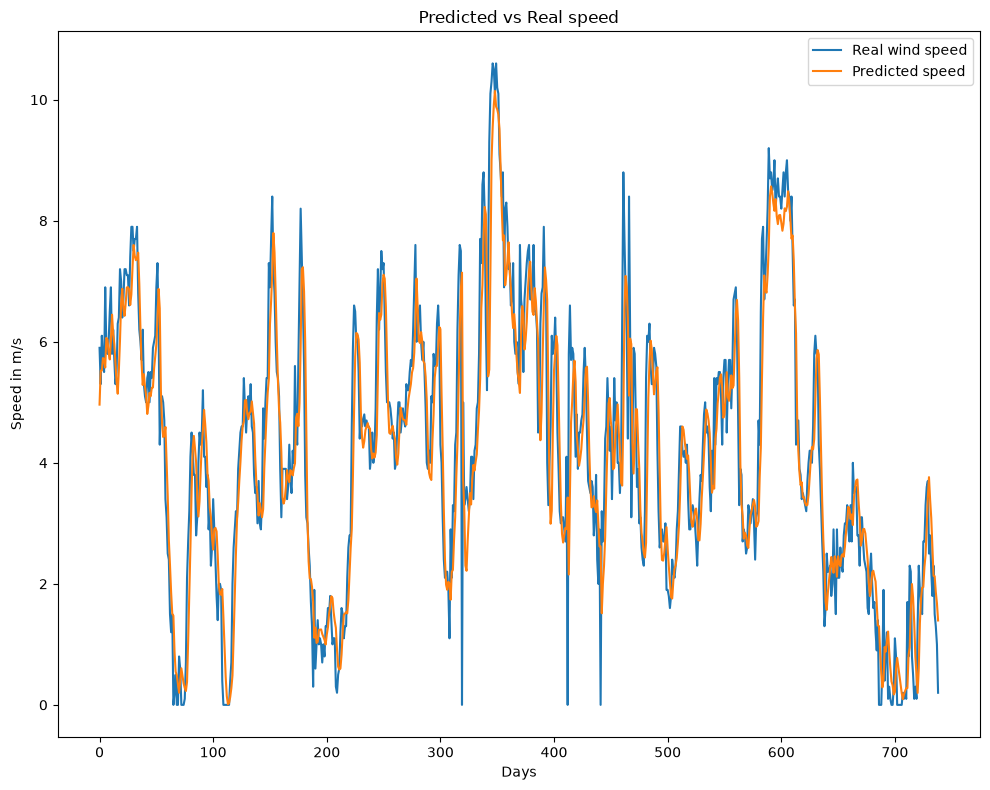

In [67]:
plt.figure(figsize=(10, 8))
plt.plot(real_speed, label='Real wind speed')
plt.plot(predicted_speed, label='Predicted speed')
plt.xlabel('Days')
plt.ylabel('Speed in m/s')
plt.title('Predicted vs Real speed')
plt.legend()
plt.tight_layout()
plt.show()